# 02 — Windowed land-suitability analysis

This notebook maps developable land for the Indonesia captive-RE workflow from the
GARUDA suitability-score raster (`landcover_suitability.tif`). The `garudata.land`
engine streams the raster in windows **in its native CRS** — no whole-raster loads,
no reprojection — so the same code path scales from this 10,000 × 10,000 layer to the
22 GB national land-cover products it was validated on. We inspect the layer,
aggregate suitable area onto the ERA5 0.25° grid over NTT, resolve it by score
class, and finish with the 0.01° siting grid that notebook 03 reuses.

Imports and paths — `garudata` is installed from the repo root, and paths are
relative to `example_notebooks/`.

In [1]:
import os
import warnings

# rasterio 1.5 sets array .shape internally, deprecated in numpy 2.5 — not ours
warnings.filterwarnings("ignore", category=DeprecationWarning,
                        message="Setting the shape on a NumPy array")

import numpy as np
import pandas as pd
import rasterio
import rasterio.windows
import matplotlib.pyplot as plt

from garudata import grids, land
from garudata.profiles import indonesia as idn

RASTER = "../landcover_suitability.tif"
OUT_DIR = "_out/nb02"
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Inspect the suitability layer

The layer is a full-Indonesia **suitability-score** raster in the GARUDA
`tools/candidate_land.py` convention — scores, not raw KLHK land-cover codes.
`garudata.profiles.indonesia.SUITABILITY_SCORES` records the semantics: score 2 is
suitable including shrub and savanna (the `--min-suitable` default keep-set is
score ≥ 2), score 3 restricts to settlement/farm/bare land, and score 0 conflates
"unsuitable" with nodata (the product ships `nodata=0`). We check CRS, size,
resolution and nodata with `rasterio`, then estimate the value distribution from a
4 × 4 sample of 1000-pixel windows — windowed reads are all this analysis ever
needs.

In [2]:
with rasterio.open(RASTER) as src:
    print(f"CRS     {src.crs}")
    print(f"size    {src.width} x {src.height} px")
    print(f"res     {src.res[0]:.5f} x {src.res[1]:.5f} deg/px")
    print(f"bounds  W {src.bounds.left:.2f}  S {src.bounds.bottom:.2f}"
          f"  E {src.bounds.right:.2f}  N {src.bounds.top:.2f}")
    print(f"dtype   {src.dtypes[0]}, nodata={src.nodata}, band count={src.count}")

CRS     EPSG:4326
size    10000 x 10000 px
res     0.00462 x 0.00169 deg/px
bounds  W 95.01  S -11.01  E 141.19  N 5.91
dtype   float32, nodata=0.0, band count=1


Score semantics and a sampled value histogram (16 windows of 1000 × 1000 px,
spread across the raster):

In [3]:
for score, meaning in idn.SUITABILITY_SCORES.items():
    print(f"score {score}: {meaning}")

counts = {}
with rasterio.open(RASTER) as src:
    step_r, step_c = src.height // 4, src.width // 4
    for i in range(4):
        for j in range(4):
            win = rasterio.windows.Window(j * step_c, i * step_r, 1000, 1000)
            vals, cnts = np.unique(src.read(1, window=win), return_counts=True)
            for v, c in zip(vals, cnts):
                counts[int(v)] = counts.get(int(v), 0) + int(c)

hist = pd.DataFrame({
    "score": sorted(counts),
    "label": [idn.SUITABILITY_SCORES[s] for s in sorted(counts)],
    "sampled_px": [counts[s] for s in sorted(counts)],
})
hist["share_pct"] = (100 * hist["sampled_px"] / hist["sampled_px"].sum()).round(2)
hist

score 0: unsuitable / nodata (conflated in this product)
score 2: suitable incl. shrub & savanna
score 3: suitable, settlement/farm/bare land only (strict)


,score,label,sampled_px,share_pct
0,0,unsuitable / nodata (conflated in this product),13661441,85.38
1,2,suitable incl. shrub & savanna,1166462,7.29
2,3,"suitable, settlement/farm/bare land only (strict)",1172097,7.33


## 2. Suitable area per ERA5 cell (NTT)

`grids.era5_grid` reconstructs the fixed 0.25° cell centers for the NTT box, and
`land.suitable_area_by_cell` collapses a keep-set of scores into one "suitable"
class: a single windowed pass yields suitable km² and fraction-of-cell-area per
grid cell. The raster spans all Indonesia while the target grid covers only NTT —
block samples outside the grid extent are **dropped** by the engine (never snapped
to edge cells), so NTT edge cells match a full-Indonesia-grid run exactly. We run
the default keep-set (score ≥ 2) and the strict variant (score 3 only).

In [4]:
lons, lats = grids.era5_grid(idn.BBOX_NTT)
print(f"ERA5 grid: {lons.size} x {lats.size} cells, "
      f"lon {lons[0]}..{lons[-1]}, lat {lats[0]}..{lats[-1]}")

suit = land.suitable_area_by_cell(RASTER, idn.SUITABLE_SCORES, lons, lats)
suit_strict = land.suitable_area_by_cell(RASTER, idn.SUITABLE_SCORES_STRICT, lons, lats)
suit

ERA5 grid: 17 x 11 cells, lon 121.0..125.0, lat -8.5..-11.0


<xarray.Dataset> Size: 5kB
Dimensions:    (lat: 11, lon: 17)
Coordinates:
  * lat        (lat) float64 88B -11.0 -10.75 -10.5 -10.25 ... -9.0 -8.75 -8.5
  * lon        (lon) float64 136B 121.0 121.2 121.5 121.8 ... 124.5 124.8 125.0
Data variables:
    area       (lat, lon) float64 1kB 0.0 0.0 0.0 0.0 ... 219.2 174.8 70.1 0.0
    fraction   (lat, lon) float64 1kB 0.0 0.0 0.0 0.0 ... 0.2282 0.09152 0.0
    cell_area  (lat, lon) float64 1kB 760.3 760.3 760.3 ... 766.0 766.0 766.0
Attributes:
    source_raster:         ../landcover_suitability.tif
    window_px:             8192
    block_px:              10
    pixel_area_mode:       cos-lat (geographic CRS)
    n_exclusion_samplers:  0
    units:                 km2 per cell per class; fraction of geometric cell...
    method:                windowed native-CRS read -> block-center samples -...

Suitable area (km² per cell) and the fraction of each cell's geometric area,
default keep-set:

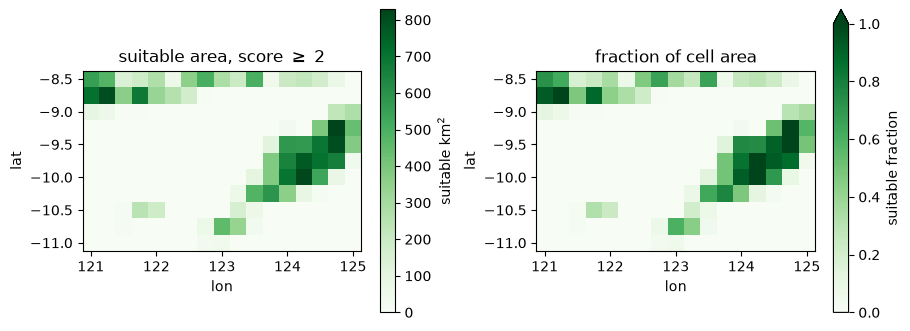

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), constrained_layout=True)
suit.area.plot(ax=axs[0], cmap="Greens", cbar_kwargs={"label": "suitable km$^2$"})
suit.fraction.plot(ax=axs[1], cmap="Greens", vmin=0, vmax=1,
                   cbar_kwargs={"label": "suitable fraction"})
axs[0].set_title(r"suitable area, score $\geq$ 2")
axs[1].set_title("fraction of cell area")
for ax in axs:
    ax.set_aspect("equal")
plt.show();

Totals for the two keep-sets:

In [6]:
totals = pd.DataFrame({
    "keep_set": ["score >= 2 (standard)", "score == 3 (strict)"],
    "suitable_km2": [float(suit.area.sum()), float(suit_strict.area.sum())],
})
totals["share_of_standard_pct"] = (100 * totals["suitable_km2"]
                                   / totals["suitable_km2"].iloc[0]).round(1)
totals.round(1)

,keep_set,suitable_km2,share_of_standard_pct
0,score >= 2 (standard),22144.3,100.0
1,score == 3 (strict),5996.0,27.1


## 3. Class-resolved areas

`land.class_area_by_cell` is the general engine underneath: it accumulates
per-(cell, class) areas in one pass, so score-2 and score-3 land can be reported
**separately** — something a binary suitability mask (geodata's `Mask`) cannot
represent. Here `"standard"` is score 2 exactly and `"strict_only"` is score 3;
their sum reproduces the binary score ≥ 2 run from section 2.

In [7]:
classes = land.class_area_by_cell(RASTER, {2: "standard", 3: "strict_only"},
                                  lons, lats)
print(f"standard + strict_only = {float(classes.area.sum()):,.1f} km2 "
      f"(binary score >= 2 run: {float(suit.area.sum()):,.1f} km2)")
classes.area.sum(("lat", "lon")).to_dataframe().round(1)

standard + strict_only = 22,144.3 km2 (binary score >= 2 run: 22,144.3 km2)


,area
land_class,
standard,16148.3
strict_only,5996.0


Per-class maps on a shared color scale:

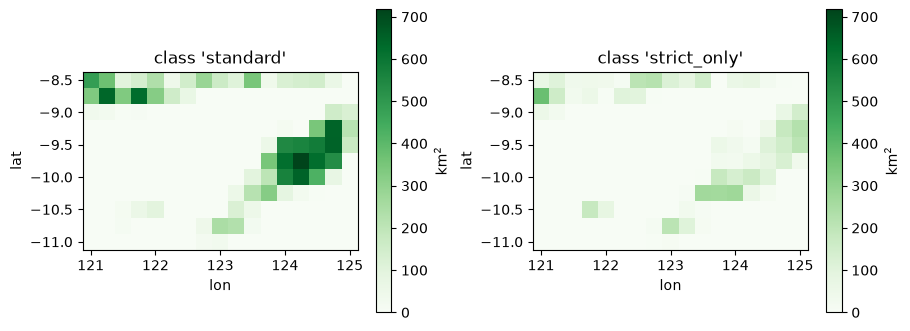

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), constrained_layout=True)
vmax = float(classes.area.max())
for ax, cls in zip(axs, classes.land_class.values):
    classes.area.sel(land_class=cls).plot(ax=ax, cmap="Greens", vmin=0, vmax=vmax,
                                          cbar_kwargs={"label": "km$^2$"})
    ax.set_title(f"class '{cls}'")
    ax.set_aspect("equal")
plt.show();

## 4. A 0.01° siting grid

Facility-level siting needs finer resolution than ERA5 cells. Same engine, denser
target grid: 0.01° cell centers across the NTT box, with `block=1` so every sample
is a single native pixel (~0.0046° × 0.0017°, about 13 samples per cell). Each cell
catches 12–18 whole-pixel samples, so individual-cell fractions are quantized (up
to ~±40% on a single cell, and occasionally > 1) while **totals are conserved**; we
clip the display at 1. The total also sits below section 2's because the ERA5
grid's edge cells extend half a step beyond the bbox (a 4.25° × 2.75° footprint vs
exactly 4° × 2.5° here). The result is saved for notebook 03.

In [9]:
w, s, e, n = idn.BBOX_NTT
flons = np.round(np.arange(w + 0.005, e, 0.01), 4)
flats = np.round(np.arange(s + 0.005, n, 0.01), 4)

fine = land.suitable_area_by_cell(RASTER, idn.SUITABLE_SCORES, flons, flats, block=1)

fine_path = os.path.join(OUT_DIR, "suitability_ntt_001deg.nc")
fine.to_netcdf(fine_path)
print(f"{flons.size} x {flats.size} cells -> {fine_path} "
      f"({os.path.getsize(fine_path) / 1e6:.1f} MB)")
print(f"total suitable (score >= 2): {float(fine.area.sum()):,.0f} km2")

400 x 250 cells -> _out/nb02/suitability_ntt_001deg.nc (2.4 MB)
total suitable (score >= 2): 19,050 km2


Suitable fraction at 0.01°:

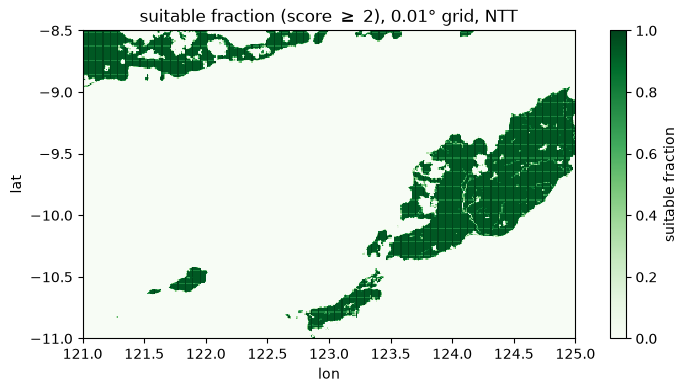

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
fine.fraction.clip(0, 1).plot.imshow(ax=ax, cmap="Greens", vmin=0, vmax=1,
                                     cbar_kwargs={"label": "suitable fraction"})
ax.set_title(r"suitable fraction (score $\geq$ 2), 0.01$\degree$ grid, NTT")
ax.set_aspect("equal")
plt.show();

## Next steps

Notebook 03 reuses `_out/nb02/suitability_ntt_001deg.nc` to allocate suitable land
around facilities. When slope or protected-area filters are needed, pass
`land.terrain_sampler` / `land.polygon_sampler` as `exclusion_samplers` — they run
inside the same windowed pass, and nodata samples never pass.